In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load only the main table
df = pd.read_csv('../data/raw/application_train.csv')

print("Shape:", df.shape)                     # (~307511, 122)
print(df.head())
print(df.info())
print("Missing %:\n", df.isnull().mean().sort_values(ascending=False).head(20))

Shape: (307511, 122)
   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      100002       1         Cash loans           M            N   
1      100003       0         Cash loans           F            N   
2      100004       0    Revolving loans           M            Y   
3      100006       0         Cash loans           F            N   
4      100007       0         Cash loans           M            N   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             0          202500.0    406597.5      24700.5   
1               N             0          270000.0   1293502.5      35698.5   
2               Y             0           67500.0    135000.0       6750.0   
3               Y             0          135000.0    312682.5      29686.5   
4               Y             0          121500.0    513000.0      21865.5   

   ...  FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOCUMENT_20 FLAG_DOCUMENT_21  \
0  ...          

In [2]:
print(df.columns)

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='str', length=122)


TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


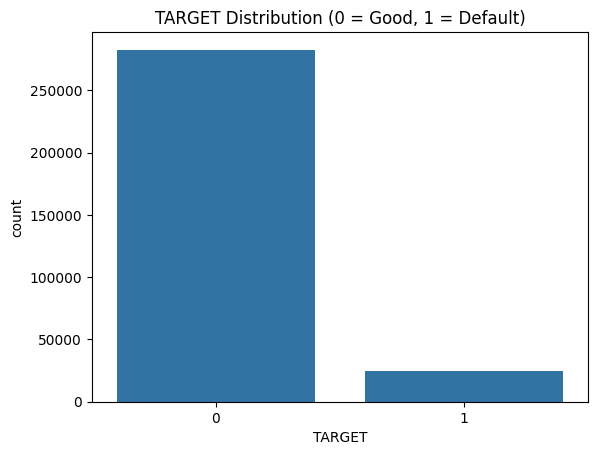

In [3]:
# Target distribution (very imbalanced!)
print(df['TARGET'].value_counts(normalize=True))
sns.countplot(x='TARGET', data=df)
plt.title('TARGET Distribution (0 = Good, 1 = Default)')
plt.show()

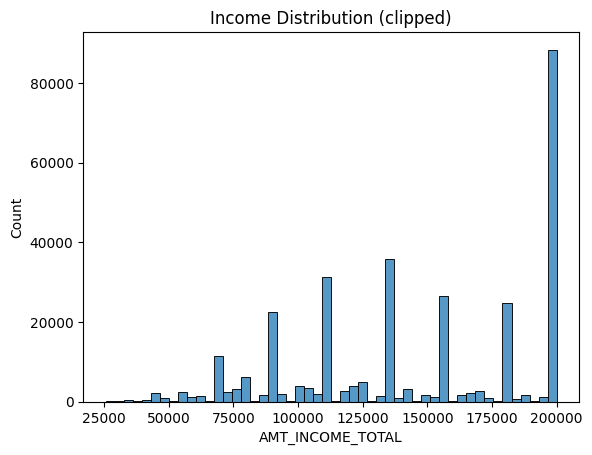

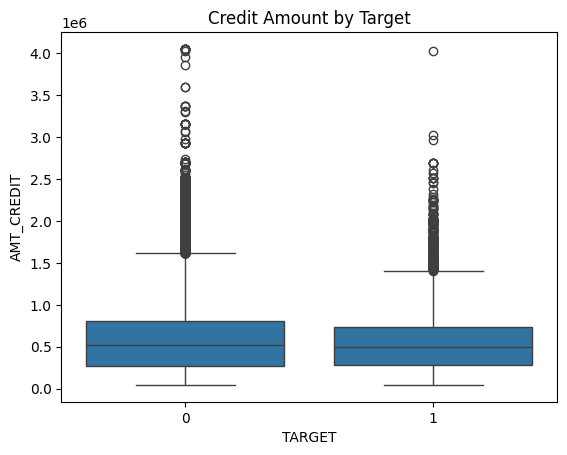

In [4]:
# Example plots
sns.histplot(df['AMT_INCOME_TOTAL'].clip(upper=200000), bins=50)
plt.title('Income Distribution (clipped)')
plt.show()

sns.boxplot(x='TARGET', y='AMT_CREDIT', data=df)
plt.title('Credit Amount by Target')
plt.show()

C:\Users\sharo\AppData\Local\Temp\ipykernel_54604\470172164.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['DOC_COUNT'] = df.filter(like='FLAG_DOCUMENT_').sum(axis=1)


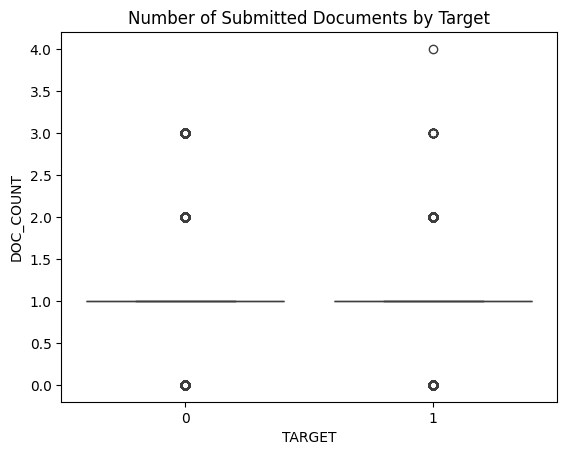

In [5]:
# Flag documents sum (simple engineered feature example)
df['DOC_COUNT'] = df.filter(like='FLAG_DOCUMENT_').sum(axis=1)
sns.boxplot(x='TARGET', y='DOC_COUNT', data=df)
plt.title('Number of Submitted Documents by Target')
plt.show()